In [1]:
# Some basic setup:
# Setup detectron2 logger

import detectron2
#!pip install fvcore iopath
#!pip install opencv-python-headless
from detectron2.utils.logger import setup_logger
setup_logger()

# import some common libraries
import os
import numpy as np
import cv2
import random
import matplotlib.pyplot as plt
import json

# import some common detectron2 utilities
from detectron2 import model_zoo
from detectron2.engine import DefaultPredictor
from detectron2.config import get_cfg
from detectron2.utils.visualizer import Visualizer
from detectron2.data import MetadataCatalog, DatasetCatalog

In [25]:
#Register the dataset
# Import `register_coco_instances()` function
from detectron2.data.datasets import register_coco_instances

# Register our coco dataset format by giving the directory folder
#register_coco_instances("tomato_calyx", {}, "./images/export_19_project.json", "./images")

#register_coco_instances("tomato_calyx_coco_matched_json", {}, "./images/coco_new_matched.json", "./images")

register_coco_instances("tomato_calyx_coco_matched_train_json", {}, "./images/coco_new_matched_train.json", "./images")
register_coco_instances("tomato_calyx_coco_matched_test_json", {}, "./images/coco_new_matched_test.json", "./images")

In [30]:
#After the coco format of the dataset is registered, now we can create the dataset & metadata catalog
# Import `MetadataCatalog` and `DatasetCatalog`
from detectron2.data import MetadataCatalog, DatasetCatalog

# Create Metadata & Dataset Catalog
tomato_calyx_metadata = MetadataCatalog.get("tomato_calyx_coco_matched_json")
dataset_dicts = DatasetCatalog.get("tomato_calyx_coco_matched_json")

tomato_calyx_metadata_train = MetadataCatalog.get("tomato_calyx_coco_matched_train_json")
tomato_calyx_metadata_test = MetadataCatalog.get("tomato_calyx_coco_matched_test_json")
dataset_dicts_train = DatasetCatalog.get("tomato_calyx_coco_matched_train_json")
dataset_dicts_test = DatasetCatalog.get("tomato_calyx_coco_matched_test_json")

[10/14 11:07:02 d2.data.datasets.coco]: Loaded 122 images in COCO format from ./images/coco_new_matched.json
[10/14 11:07:02 d2.data.datasets.coco]: Loaded 100 images in COCO format from ./images/coco_new_matched_train.json
[10/14 11:07:02 d2.data.datasets.coco]: Loaded 22 images in COCO format from ./images/coco_new_matched_test.json


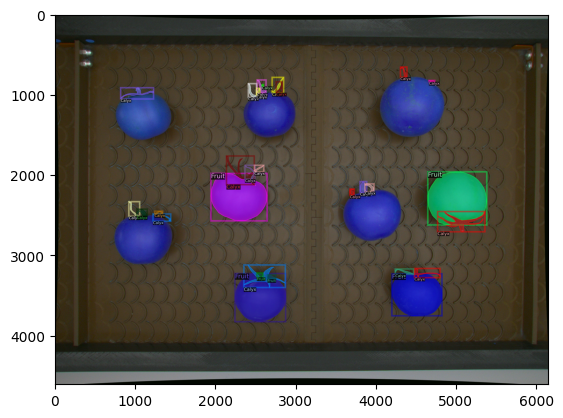

In [27]:
#let's visualize the annotations of randomly selected samples in the dataset:
from detectron2.utils.visualizer import Visualizer
import random


for d in random.sample(dataset_dicts_train, 1):
    img = cv2.imread(d["file_name"])
    visualizer = Visualizer(img[:, :, ::-1],
                            metadata=tomato_calyx_metadata,
                            scale=3)
    vis = visualizer.draw_dataset_dict(d)
    plt.imshow(vis.get_image()[:, :, ::-1])
    plt.show()

In [28]:
#Now, let's fine tune a coco-pretrained R-50 FPN Mask R-CNN Model to our dataset.
# Import DefaultTrainer from engine & config function
from detectron2.engine import DefaultTrainer
from detectron2.config import get_cfg

# Mask R-CNN Model used
mrcnn_model = "COCO-InstanceSegmentation/mask_rcnn_R_50_FPN_3x.yaml"

# Set configuration
cfg = get_cfg()
cfg.merge_from_file(model_zoo.get_config_file(mrcnn_model))
cfg.DATASETS.TRAIN = ("tomato_calyx_coco_matched_train_json",)
cfg.DATASETS.TEST = ("tomato_calyx_coco_matched_test_json",)   # no metrics implemented for this dataset
cfg.DATALOADER.NUM_WORKERS = 2
cfg.MODEL.WEIGHTS = model_zoo.get_checkpoint_url(mrcnn_model) # initialize from model zoo
cfg.SOLVER.IMS_PER_BATCH = 2
cfg.SOLVER.BASE_LR = 0.00025
cfg.SOLVER.MAX_ITER = 1500    # 1000 = good 
cfg.SOLVER.STEPS = []
cfg.MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE = 128   #30 = good # faster, and good enough for this toy dataset
cfg.MODEL.ROI_HEADS.NUM_CLASSES = 2  # 2 classes (calyx, fruit)

# TRAINING: Create output folder & TRAIN!
os.makedirs(cfg.OUTPUT_DIR, exist_ok=True)
trainer = DefaultTrainer(cfg)
trainer.resume_or_load(resume=False)
trainer.train()

#cfg.OUTPUT_DIR = "output"
#print(cfg.OUTPUT_DIR)
#print(os.getcwd())

[10/14 10:55:20 d2.engine.defaults]: Model:
GeneralizedRCNN(
  (backbone): FPN(
    (fpn_lateral2): Conv2d(256, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output2): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral3): Conv2d(512, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output3): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral4): Conv2d(1024, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output4): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral5): Conv2d(2048, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output5): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (top_block): LastLevelMaxPool()
    (bottom_up): ResNet(
      (stem): BasicStem(
        (conv1): Conv2d(
          3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False
          (norm): FrozenBatchNorm2d(num_features=64, eps=1e-05)
        )
      )
      (res

Skip loading parameter 'roi_heads.box_predictor.cls_score.weight' to the model due to incompatible shapes: (81, 1024) in the checkpoint but (3, 1024) in the model! You might want to double check if this is expected.
Skip loading parameter 'roi_heads.box_predictor.cls_score.bias' to the model due to incompatible shapes: (81,) in the checkpoint but (3,) in the model! You might want to double check if this is expected.
Skip loading parameter 'roi_heads.box_predictor.bbox_pred.weight' to the model due to incompatible shapes: (320, 1024) in the checkpoint but (8, 1024) in the model! You might want to double check if this is expected.
Skip loading parameter 'roi_heads.box_predictor.bbox_pred.bias' to the model due to incompatible shapes: (320,) in the checkpoint but (8,) in the model! You might want to double check if this is expected.
Skip loading parameter 'roi_heads.mask_head.predictor.weight' to the model due to incompatible shapes: (80, 256, 1, 1) in the checkpoint but (2, 256, 1, 1) in

[10/14 10:55:20 d2.engine.train_loop]: Starting training from iteration 0


/home/sagemaker-user/.conda/envs/detectron2/lib/python3.9/site-packages/torch/functional.py:504: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at ../aten/src/ATen/native/TensorShape.cpp:3526.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


[10/14 10:55:30 d2.utils.events]:  eta: 0:09:34  iter: 19  total_loss: 3.315  loss_cls: 1.303  loss_box_reg: 0.8399  loss_mask: 0.6912  loss_rpn_cls: 0.4744  loss_rpn_loc: 0.08269    time: 0.3918  last_time: 0.3914  data_time: 0.0208  last_data_time: 0.0037   lr: 4.9953e-06  max_mem: 2243M
[10/14 10:55:39 d2.utils.events]:  eta: 0:09:32  iter: 39  total_loss: 3.29  loss_cls: 1.192  loss_box_reg: 0.8829  loss_mask: 0.683  loss_rpn_cls: 0.4615  loss_rpn_loc: 0.0963    time: 0.3977  last_time: 0.3265  data_time: 0.0036  last_data_time: 0.0038   lr: 9.9902e-06  max_mem: 2243M
[10/14 10:55:47 d2.utils.events]:  eta: 0:09:20  iter: 59  total_loss: 2.787  loss_cls: 0.9789  loss_box_reg: 0.8382  loss_mask: 0.6681  loss_rpn_cls: 0.199  loss_rpn_loc: 0.1101    time: 0.3955  last_time: 0.4471  data_time: 0.0036  last_data_time: 0.0035   lr: 1.4985e-05  max_mem: 2243M
[10/14 10:55:54 d2.utils.events]:  eta: 0:09:10  iter: 79  total_loss: 2.439  loss_cls: 0.7909  loss_box_reg: 0.836  loss_mask: 0.6

## Calculation of IoU

[10/14 14:52:05 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from ./output/model_final.pth ...


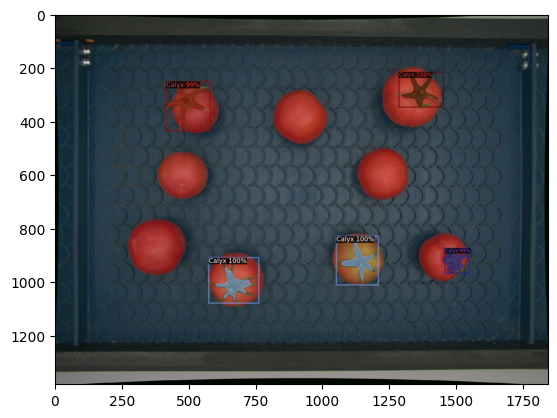

./images/P00000000879565588619405_250205_110201_333906.png


In [148]:
#Inference & Evaluation using trained model (specific image)

#Select specific sample
sample = dataset_dicts_test[10]

# Load model weights
cfg.MODEL.WEIGHTS = os.path.join(cfg.OUTPUT_DIR, 'model_final.pth')
cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = 0.6   # set the testing threshold for this model default=0.6
cfg.DATASETS.TEST = ("tomato_calyx_coco_matched_test_json",)

# Create Predictor for inference
predictor = DefaultPredictor(cfg)

#Now we will use predictor to inference and visualize it's output
from detectron2.utils.visualizer import ColorMode

d = sample
im = cv2.imread(d["file_name"])
im = cv2.cvtColor(im, cv2.COLOR_BGR2RGB)
outputs = predictor(im)
v = Visualizer(im[:, :, ::-1],
               metadata=tomato_calyx_metadata,
               scale=0.9,
               # remove the colors of unsegmented pixels
               instance_mode=ColorMode.IMAGE)
v = v.draw_instance_predictions(outputs["instances"].to("cpu"))
plt.imshow(v.get_image()[:, :, ::-1])
plt.show()
print(d["file_name"])

torch.Size([5, 1536, 2048])
5


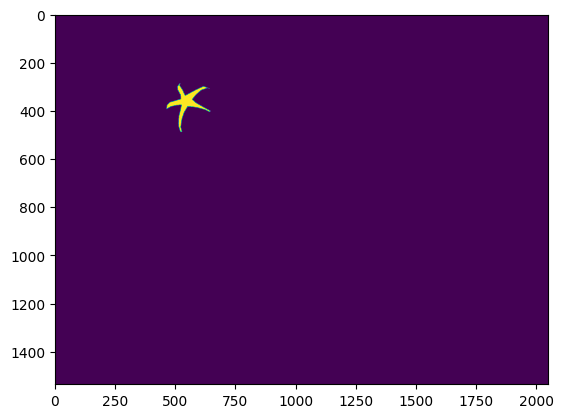

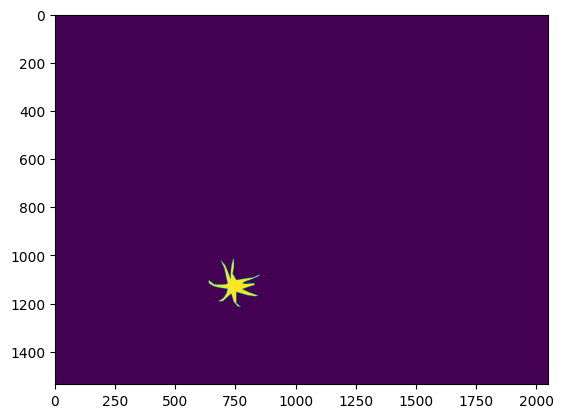

./images/P00000000879565588619405_250205_110201_333906.png


In [149]:
#Convert annotation polygons into bitmasks and create a mask tensor

#!pip install pycocotools
from pycocotools import mask as mask_util
import torch

ann_image = sample

height = ann_image['height']
width = ann_image['width']

list_of_tensors = []

for item in ann_image['annotations']:
    polygon = item['segmentation']
    rles = mask_util.frPyObjects(polygon, height, width)
    rle = mask_util.merge(rles)
    bitmask = mask_util.decode(rle)

    list_of_tensors.append(torch.from_numpy(bitmask))

bitmask_tensor = torch.stack(list_of_tensors, dim=0)

print(bitmask_tensor.shape)
print(len(list_of_tensors))

for i in range(2):
    plt.imshow(bitmask_tensor[i,:,:])
    plt.show()

print(ann_image['file_name'])

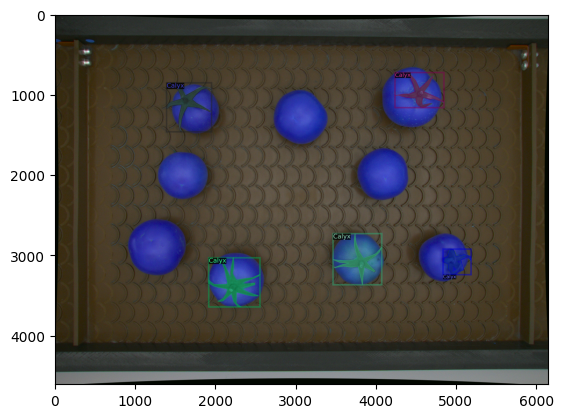

In [150]:
#let's visualize the annotations:

d = sample
img = cv2.imread(d["file_name"])
visualizer = Visualizer(img[:, :, ::-1],
                        metadata=tomato_calyx_metadata,
                        scale=3)
vis = visualizer.draw_dataset_dict(d)
plt.imshow(vis.get_image()[:, :, ::-1])
plt.show()

In [151]:
# Calculate IoU
import torch

# Prediction masks
instances = outputs["instances"].to("cpu")
pred_masks = instances.pred_masks.bool()      # (N_pred, H, W)

# Ground truth masks
gt_masks = bitmask_tensor.bool()  # (N_gt, H, W)

# Get the number of prediction and ground truth masks in the tensors
num_preds = pred_masks.shape[0]
num_gts = gt_masks.shape[0]

iou_matrix = torch.zeros((num_preds, num_gts))

for i in range(num_preds):
    for j in range(num_gts):

        intersection = torch.logical_and(
            pred_masks[i],
            gt_masks[j]
        ).sum().float()

        union = torch.logical_or(
            pred_masks[i],
            gt_masks[j]
        ).sum().float()

        if union > 0:
            iou_matrix[i, j] = intersection / union

print(iou_matrix.round(decimals=2))

tensor([[0.0000, 0.0000, 0.0000, 0.0000, 0.8000],
        [0.0000, 0.0000, 0.7500, 0.0000, 0.0000],
        [0.0000, 0.5800, 0.0000, 0.0000, 0.0000],
        [0.8000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.0000, 0.0000, 0.0000, 0.8100, 0.0000]])


In [152]:
#Compute the mean IoU over predicted instances in the image
max_line = torch.max(iou_matrix, dim=1)
print(max_line.values)
torch.mean(max_line.values)

tensor([0.8045, 0.7453, 0.5766, 0.8046, 0.8128])


tensor(0.7488)

## Split the dataset into training/test

In [23]:
# Split the dataset into training/test

with open ("./images/coco_new_matched.json", "r") as f:
    annotations_dict = json.load(f)
#print(annotations_dict)

#Get 22 images fpr testing
test_dict = {'images': annotations_dict['images'][:22]} # -> from 0 to 21: 'id':6943 
test_dict['annotations'] = annotations_dict['annotations'][0:390] # from 0 to 389
test_dict['categories'] = annotations_dict['categories']

#Get 100 images for training
train_dict = {'images': annotations_dict['images'][22:]} # -> from 22 to end: 'id':6944 
train_dict['annotations'] = annotations_dict['annotations'][390:] # from 390 to end
train_dict['categories'] = annotations_dict['categories']

In [24]:
#Dump the dictionaries into respective JSON file
with open("./images/coco_new_matched_test.json", "w") as file:
    json.dump(test_dict, file)
with open("./images/coco_new_matched_train.json", "w") as file:
    json.dump(train_dict, file)